# 05 — Evaluation

**Question:** how robust are the phase 6 conclusions? In particular, is "GPS adds no forecasting skill beyond past seismicity" an artefact of how we scored or set up the models?

Phase 6 (`04_models`) scored expected counts and probabilities with single numbers over one setup. This notebook:

1. Scores **whole predictive distributions** for counts, not just the expected count.
2. Scores probability forecasts completely: **skill against climatology, ranking (ROC and precision-recall AUC), calibration**, and recalibrated versions of every forecaster.
3. States **the smallest difference each test could detect**, so "no gain" has a size.
4. Repeats the GPS ablation under **different setups**: training start, training window, forecast horizon, magnitude threshold.
5. Summarises everything for the README.

Forecasts come from `src/experiments.py`, which runs each forecaster through the same walk-forward evaluation as before and caches the results in `data/processed/forecasts/` (delete that folder to recompute). Every result is reported for **2020–2025** (312 weeks) and for the **steady period 2024–2025** (104 weeks), when the rate of seismicity changed least: over 2020–2025 some scores are flattered simply by telling quiet years from busy ones.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation import (add_horizon_targets, add_threshold_targets, count_scores, distribution_scores,
                            paired_difference, poisson_deviance, rolling_dispersion, weekly_poisson_deviance)
from src.experiments import MAIN, SENSITIVITY, run
from src.features import build_features

warnings.filterwarnings("ignore", category=RuntimeWarning)
events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
# The table runs to late January 2026 so that 4-week targets exist for the last test weeks.
table = build_features(events, gps, "2005-01-03", "2026-01-25")
table = add_threshold_targets(add_horizon_targets(table, 4), events, 2.5, "25")

TEST_START, TEST_END, STEADY_START = "2020-01-06", "2025-12-22", "2024-01-01"
# The main forecasts start in 2017, so that each test week has past forecasts to calibrate on.
main = run(table, MAIN, "2017-01-02", TEST_END)
test = table.loc[TEST_START:TEST_END]
steady = test.index >= STEADY_START
periods = {"2020–2025": np.ones(len(test), bool), "2024–2025": steady}
print(f"{len(test)} test weeks; {steady.sum()} in 2024–2025. Count forecasters: {list(main['counts'].columns)}")
print(f"Probability forecasters: {list(main['probs'].columns)}")

312 test weeks; 104 in 2024–2025. Count forecasters: ['rolling_mean_4w', 'glm_seismic', 'glm_all', 'paper_rate', 'lgbm_seismic']
Probability forecasters: ['climatology_52w', 'bar', 'recalibrated', 'recalibrated_gps']


## 1. Full predictive distributions for counts

A count forecast so far was one number, the expected count μ. A useful forecast should also say **how uncertain** it is. A Poisson distribution with mean μ has variance μ, which is far too little for a swarm-prone volcano. The **negative binomial** (NB) adds a dispersion parameter α: variance = μ + α·μ². With α = 0 it is the Poisson distribution.

For each count model, α is fitted (by maximum likelihood) on the **104 weeks before each test week**: how much the observed counts scattered around that model's own earlier forecasts. Forecasts from 2017 on provide those earlier weeks, so no test week is used for its own α.

Scores for whole distributions (lower is better for both):

- **Log score:** −log of the probability the forecast gave to the count that happened.
- **Ranked probability score (RPS):** for every threshold k, the squared difference between the forecast P(count ≤ k) and what happened (0 or 1), summed over k: the Brier score summed over all thresholds.

Calibration checks:

- **Coverage:** how often the count fell inside the central 80% and 95% prediction intervals (should be 80% and 95%).
- **PIT histogram:** where each observed count fell within its forecast distribution (0 = far below, 1 = far above). If the distributions are right, every value is equally likely and the histogram is flat. A U shape means the forecasts are too narrow (counts keep landing in the tails).

In [2]:
y_all = table.loc["2017-01-02":TEST_END, "count"]
counts = main["counts"]
dispersion = {name: rolling_dispersion(y_all, counts[name], TEST_START) for name in counts.columns}
dist = {name: {"NB": distribution_scores(test["count"], counts[name].loc[TEST_START:], dispersion[name]),
               "Poisson": distribution_scores(test["count"], counts[name].loc[TEST_START:], 1e-4)}
        for name in counts.columns}

rows = {}
for name in counts.columns:
    for family in ["Poisson", "NB"]:
        d = dist[name][family]
        rows[(name, family)] = {
            **{f"log_score {p}": d["log_score"][m].mean() for p, m in periods.items()},
            **{f"rps {p}": d["rps"][m].mean() for p, m in periods.items()},
            "in_80 (2020–25)": d["in_80"].mean(), "in_95 (2020–25)": d["in_95"].mean(),
        }
pd.DataFrame(rows).T.round(2)

log_score 2020–2025  log_score 2024–2025  \
rolling_mean_4w Poisson                 9.14                16.32   
                NB                      3.44                 4.51   
glm_seismic     Poisson                 8.44                14.74   
                NB                      3.36                 4.38   
glm_all         Poisson                 8.57                15.10   
                NB                      3.37                 4.40   
paper_rate      Poisson                10.93                19.02   
                NB                      4.07                 4.76   
lgbm_seismic    Poisson                 9.16                16.15   
                NB                      3.40                 4.43   

                         rps 2020–2025  rps 2024–2025  in_80 (2020–25)  \
rolling_mean_4w Poisson          10.54          21.51             0.45   
                NB                8.41          16.85             0.86   
glm_seismic     Poisson           9.96          20.53             0.45   
                NB                8.04          16.05             0.88   
glm_all         Poisson          10.14          21.19             0.45   
                NB                8.07          16.21             0.89   
paper_rate      Poisson           9.99          20.64             0.44   
                NB                9.02          18.16             0.90   
lgbm_seismic    Poisson          10.47          22.09             0.44   
                NB                8.41          16.91             0.86   

                         in_95 (2020–25)  
rolling_mean_4w Poisson             0.60  
                NB                  0.95  
glm_seismic     Poisson             0.60  
                NB                  0.96  
glm_all         Poisson             0.63  
                NB                  0.96  
paper_rate      Poisson             0.54  
                NB                  0.95  
lgbm_seismic    Poisson             0.63  
                NB                  0.96

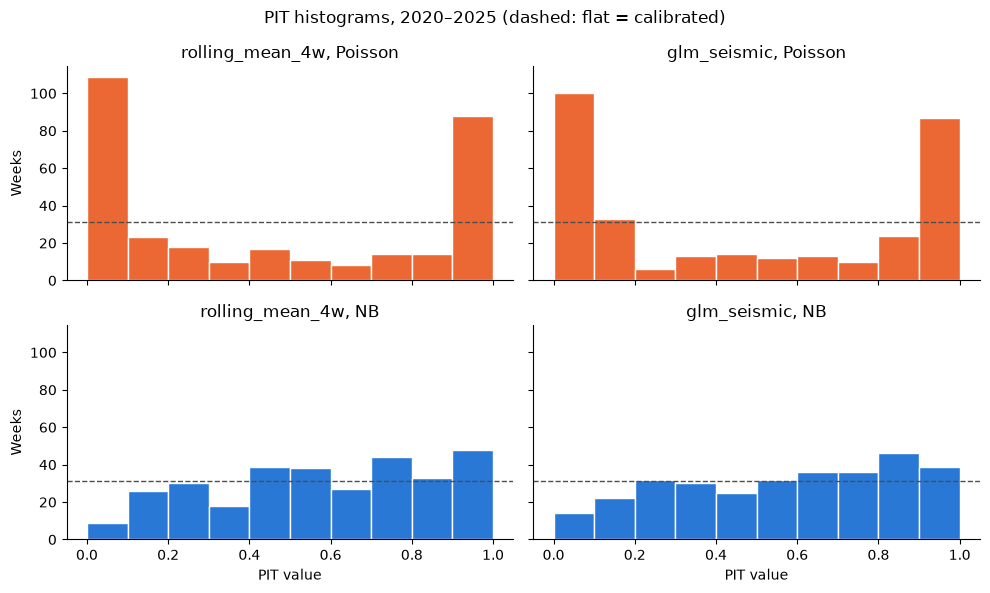

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for col, name in enumerate(["rolling_mean_4w", "glm_seismic"]):
    for row, family in enumerate(["Poisson", "NB"]):
        ax = axes[row, col]
        ax.hist(dist[name][family]["pit"], bins=10, range=(0, 1), color="#2a78d6" if family == "NB" else "#eb6834",
                edgecolor="white")
        ax.axhline(len(test) / 10, color="0.3", linewidth=1, linestyle="--")
        ax.set_title(f"{name}, {family}")
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("PIT value")
for ax in axes[:, 0]:
    ax.set_ylabel("Weeks")
fig.suptitle("PIT histograms, 2020–2025 (dashed: flat = calibrated)")
plt.tight_layout()
plt.show()

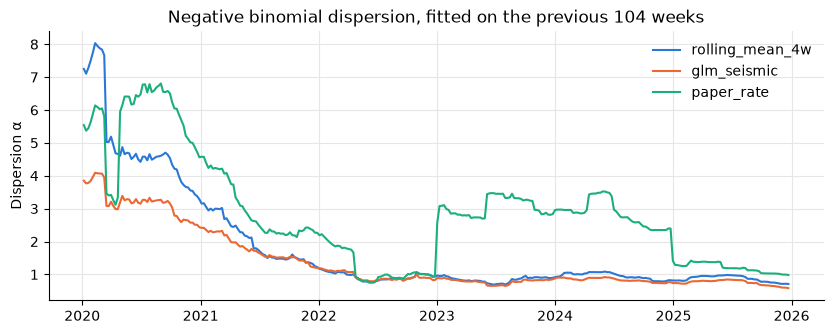

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name, colour in [("rolling_mean_4w", "#2a78d6"), ("glm_seismic", "#eb6834"), ("paper_rate", "#1baf7a")]:
    ax.plot(dispersion[name].index, dispersion[name], linewidth=1.5, color=colour, label=name)
ax.set_ylabel("Dispersion α")
ax.set_title("Negative binomial dispersion, fitted on the previous 104 weeks")
ax.grid(True, color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [5]:
# Paired comparisons of the NB scores (negative = first model better).
pairs = [("glm_all", "glm_seismic", "GPS added (GLM)"),
         ("glm_seismic", "rolling_mean_4w", "GLM (seismic) against the bar"),
         ("lgbm_seismic", "glm_seismic", "LightGBM against GLM"),
         ("paper_rate", "rolling_mean_4w", "paper's model against the bar")]
pd.concat({f"{score}, {p}": pd.DataFrame({label: paired_difference(dist[a]["NB"][score][m], dist[b]["NB"][score][m])
                                          for a, b, label in pairs}).T
           for score in ["log_score", "rps"] for p, m in periods.items()}, axis=1).round(3)

log_score, 2020–2025                 \
                                   mean_difference ci_low ci_high   
GPS added (GLM)                              0.005 -0.025   0.038   
GLM (seismic) against the bar               -0.083 -0.144  -0.027   
LightGBM against GLM                         0.043  0.009   0.080   
paper's model against the bar                0.630  0.191   1.278   

                              log_score, 2024–2025                 \
                                   mean_difference ci_low ci_high   
GPS added (GLM)                              0.022 -0.007   0.052   
GLM (seismic) against the bar               -0.128 -0.229  -0.019   
LightGBM against GLM                         0.045 -0.014   0.102   
paper's model against the bar                0.247  0.107   0.494   

                               rps, 2020–2025                 rps, 2024–2025  \
                              mean_difference ci_low ci_high mean_difference   
GPS added (GLM)                         0.029 -0.221   0.253           0.160   
GLM (seismic) against the bar          -0.368 -0.946   0.108          -0.801   
LightGBM against GLM                    0.373  0.036   0.770           0.869   
paper's model against the bar           0.610 -0.415   1.725           1.317   

                                              
                              ci_low ci_high  
GPS added (GLM)               -0.584   0.846  
GLM (seismic) against the bar -2.328   0.444  
LightGBM against GLM          -0.000   1.986  
paper's model against the bar -1.558   4.642

**What section 1 shows:**

- **Poisson forecasts are far too confident.** Their 80% intervals contained the count in only 44–45% of weeks and their 95% intervals in 54–63%; the PIT histograms are strongly U-shaped (counts keep landing in the tails). With the negative binomial, coverage is about right (86–90% and 95–96%; slightly too wide at 80%), and the log score improves from about 8–11 to 3.4–4.1.
- **The spread is large:** α settles at about 0.8–1.0 for the seismicity-based models from 2022 on. For an expected 20 events a week that is a standard deviation of about 19 (Poisson: 4.5). It was larger in 2020–2021, when weeks were mostly quiet with rare bursts. The paper's model needs a much larger α (about 3 in 2023–2024): its means miss the swarms, so the distribution has to be wider to cover them.
- **The NB histograms tilt slightly upwards:** observed counts land a little more often in the upper half of the forecast distributions. The forecasts are slightly too low on average, as expected while the rate keeps growing.
- **With whole distributions, the GLM's gain over the bar becomes significant.** On the log score, the seismic GLM beats the 4-week rolling mean by 0.083 per week over 2020–2025 (interval −0.144 to −0.027) and by 0.128 in 2024–2025 (−0.229 to −0.019). The Poisson deviance in phase 6 couldn't confirm this, because a few swarm weeks dominated it; the log score with a realistic spread is less at the mercy of those weeks. (The RPS points the same way but its intervals include zero.)
- **GPS still adds nothing:** adding GPS to the GLM changes the log score by +0.005 (interval −0.025 to +0.038) over 2020–2025 and +0.022 (−0.007 to +0.052) in 2024–2025.
- LightGBM is significantly worse than the GLM on the log score over 2020–2025, and the paper's model significantly worse than the bar, as before.

## 2. P(at least one M ≥ 3 next week), scored completely

Forecasters (all from phase 6, plus one new route):

- `climatology_52w`: the share of the last 52 weeks with an M ≥ 3.
- `bar`: the 4-week mean count converted with P = 1 − exp(−μ × share), assuming independent events.
- `recalibrated`: phase 6's best (logistic regression on log of the 4-week mean, last 3 years); `recalibrated_gps` adds the noise-corrected GPS rate.
- **New: `nb_rolling_mean_4w` and `nb_glm_seismic`**, the negative binomial route. If a week's count is NB with mean μ and dispersion α (section 1), and each event independently reaches M ≥ 3 with probability *share*, then the number of M ≥ 3 events is NB with mean μ·share and the *same* α. So P(at least one) = 1 − (1 + α·μ·share)^(−1/α). Unlike the bar, this allows for clustering: in a swarm week, many events don't make an M ≥ 3 near-certain.

Scores:

- **Brier skill score** = 1 − Brier / Brier(climatology): the share of climatology's error removed (0 = no better than climatology; negative = worse).
- **ROC AUC** (ranking; 0.5 = random) and **precision-recall AUC** (ranking judged on how well the risky weeks are found; its no-skill value is the share of weeks with an M ≥ 3, 0.14 over 2020–2025 and 0.29 in 2024–2025).
- **Reliability** (lower is better: are the probabilities right?) and **resolution** (higher is better: do they separate riskier from safer weeks?), the two parts of the Brier score.

**Recalibration as a standard step:** each forecaster also gets a recalibrated version (`+recal`): before each test week, P = sigmoid(a + b·logit(p)) is fitted on its previous 156 weeks of forecasts and outcomes (once those include 10 weeks with an M ≥ 3). This compares forecasters on what they *know*, not on how their raw probabilities happen to be scaled.

In [6]:
from src.evaluation import (nb_probability_at_least_one, probability_report, recalibrate, walk_forward)
from src.models import share_large

hist = table.loc["2017-01-02":TEST_END]
share = walk_forward(table, lambda history, current: share_large(history), "2017-01-02", TEST_END)
probs = main["probs"].copy()
for name in ["rolling_mean_4w", "glm_seismic"]:
    alpha = rolling_dispersion(hist["count"], counts[name], "2017-01-02").reindex(counts.index).bfill()
    probs[f"nb_{name}"] = nb_probability_at_least_one(counts[name], share, alpha)
raw_names = list(probs.columns)
for name in raw_names:
    probs[f"{name}+recal"] = recalibrate(probs[name], hist["has_large"], TEST_START)
probs = probs.loc[TEST_START:]

report = {p: probability_report(test["has_large"][m], {n: probs[n][m] for n in raw_names}, "climatology_52w")
          for p, m in periods.items()}
pd.concat(report, axis=1).round(3)

2020–2025                                                 \
                       brier brier_skill log_loss    auc pr_auc reliability   
climatology_52w        0.107       0.000    0.357  0.747  0.256       0.002   
bar                    0.107       0.007    0.335  0.816  0.372       0.005   
recalibrated           0.103       0.042    0.327  0.818  0.373       0.001   
recalibrated_gps       0.104       0.030    0.330  0.816  0.361       0.002   
nb_rolling_mean_4w     0.102       0.047    0.325  0.816  0.361       0.002   
nb_glm_seismic         0.107       0.006    0.339  0.801  0.329       0.002   

                                          2024–2025                       \
                   resolution uncertainty     brier brier_skill log_loss   
climatology_52w         0.017       0.119     0.209       0.000    0.610   
bar                     0.020       0.119     0.217      -0.036    0.621   
recalibrated            0.021       0.119     0.203       0.030    0.588   
recalibrated_gps        0.021       0.119     0.205       0.019    0.595   
nb_rolling_mean_4w      0.020       0.119     0.203       0.028    0.588   
nb_glm_seismic          0.017       0.119     0.215      -0.028    0.619   

                                                                     
                      auc pr_auc reliability resolution uncertainty  
climatology_52w     0.467  0.270       0.007      0.003       0.205  
bar                 0.623  0.402       0.023      0.018       0.205  
recalibrated        0.630  0.402       0.009      0.012       0.205  
recalibrated_gps    0.620  0.396       0.017      0.012       0.205  
nb_rolling_mean_4w  0.624  0.385       0.011      0.017       0.205  
nb_glm_seismic      0.584  0.345       0.015      0.006       0.205

In [7]:
# Does recalibration help? Brier skill score of each forecaster, raw and recalibrated.
pd.DataFrame({(p, version): probability_report(test["has_large"][m],
                                               {n: probs[n + ("" if version == "raw" else "+recal")][m] for n in raw_names},
                                               "climatology_52w")["brier_skill"]
              for p, m in periods.items() for version in ["raw", "recalibrated"]}).round(3)

2020–2025              2024–2025             
                         raw recalibrated       raw recalibrated
climatology_52w        0.000        0.000     0.000        0.000
bar                    0.007        0.030    -0.036        0.020
recalibrated           0.042        0.037     0.030        0.045
recalibrated_gps       0.030        0.034     0.019        0.039
nb_rolling_mean_4w     0.047        0.031     0.028        0.026
nb_glm_seismic         0.006       -0.002    -0.028       -0.011

In [8]:
happened = test["has_large"].astype(float)
clip = lambda p: np.clip(p, 1e-3, 1 - 1e-3)  # noqa: E731
brier_week = {n: (probs[n] - happened) ** 2 for n in raw_names}
logloss_week = {n: -(happened * np.log(clip(probs[n])) + (1 - happened) * np.log(1 - clip(probs[n]))) for n in raw_names}
pairs = [("nb_rolling_mean_4w", "bar", "NB conversion against the bar"),
         ("nb_rolling_mean_4w", "climatology_52w", "NB conversion against climatology"),
         ("recalibrated", "climatology_52w", "recalibrated against climatology"),
         ("nb_rolling_mean_4w", "recalibrated", "NB conversion against recalibrated"),
         ("recalibrated_gps", "recalibrated", "GPS added (recalibrated)")]
pd.concat({f"{score}, {p}": pd.DataFrame({label: paired_difference(weekly[a][m], weekly[b][m]) for a, b, label in pairs}).T
           for score, weekly in [("Brier", brier_week), ("log-loss", logloss_week)] for p, m in periods.items()},
          axis=1).round(4)

Brier, 2020–2025                  \
                                    mean_difference  ci_low ci_high   
NB conversion against the bar               -0.0042 -0.0094  0.0005   
NB conversion against climatology           -0.0050 -0.0137  0.0030   
recalibrated against climatology            -0.0045 -0.0121  0.0025   
NB conversion against recalibrated          -0.0005 -0.0035  0.0019   
GPS added (recalibrated)                     0.0013  0.0003  0.0026   

                                   Brier, 2024–2025                  \
                                    mean_difference  ci_low ci_high   
NB conversion against the bar               -0.0135 -0.0275 -0.0010   
NB conversion against climatology           -0.0059 -0.0260  0.0164   
recalibrated against climatology            -0.0063 -0.0235  0.0122   
NB conversion against recalibrated           0.0004 -0.0073  0.0070   
GPS added (recalibrated)                     0.0023  0.0007  0.0045   

                                   log-loss, 2020–2025                  \
                                       mean_difference  ci_low ci_high   
NB conversion against the bar                  -0.0101 -0.0234  0.0011   
NB conversion against climatology              -0.0321 -0.0702 -0.0034   
recalibrated against climatology               -0.0305 -0.0682 -0.0011   
NB conversion against recalibrated             -0.0016 -0.0088  0.0041   
GPS added (recalibrated)                        0.0036  0.0008  0.0074   

                                   log-loss, 2024–2025                  
                                       mean_difference  ci_low ci_high  
NB conversion against the bar                  -0.0327 -0.0668 -0.0030  
NB conversion against climatology              -0.0218 -0.0687  0.0335  
recalibrated against climatology               -0.0223 -0.0677  0.0284  
NB conversion against recalibrated              0.0004 -0.0172  0.0149  
GPS added (recalibrated)                        0.0068  0.0019  0.0139

**Reliability diagram** (2020–2025): weeks grouped by forecast probability; for each group, the mean forecast (x) against how often an M ≥ 3 happened (y). A calibrated forecaster lies on the diagonal. Marker size shows the number of weeks.

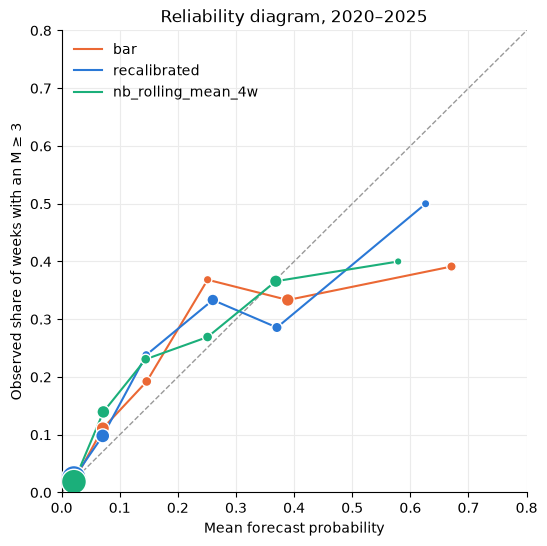

In [9]:
from src.evaluation import calibration_table

bins = (0, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="0.6", linewidth=1, linestyle="--")
for name, colour in [("bar", "#eb6834"), ("recalibrated", "#2a78d6"), ("nb_rolling_mean_4w", "#1baf7a")]:
    cal = calibration_table(test["has_large"], probs[name], bins=bins)
    ax.plot(cal["mean_forecast"], cal["observed_share"], "-", color=colour, linewidth=1.5, label=name)
    ax.scatter(cal["mean_forecast"], cal["observed_share"], s=cal["weeks"] * 2, color=colour, edgecolors="white", zorder=3)
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
ax.set_xlabel("Mean forecast probability")
ax.set_ylabel("Observed share of weeks with an M ≥ 3")
ax.set_title("Reliability diagram, 2020–2025")
ax.grid(True, color="0.92", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

**What section 2 shows:**

- **Allowing for clustering fixes the conversion without extra fitting.** The NB conversion of the 4-week mean scores as well as phase 6's recalibrated model (difference ≈ 0 on every score), but needs no classifier: only the dispersion α from section 1. It is **significantly better than the bar** in 2024–2025 (Brier −0.0135, interval −0.0275 to −0.0010; log-loss −0.033, −0.067 to −0.003). The bar's problem was the independence assumption, and the NB's α is exactly the missing clustering.
- **Skill over climatology is real but small.** Over 2020–2025 both the NB conversion and the recalibrated model beat climatology significantly on log-loss (−0.032, interval −0.070 to −0.003; −0.031, −0.068 to −0.001), but not on the Brier score, and neither difference is significant in 2024–2025. Brier skill scores are at most 0.03–0.05: the best forecasts remove 3–5% of climatology's error. In the steady period, the best ROC AUC is 0.63 and the best precision-recall AUC 0.40 (no-skill value 0.29).
- **Recalibration as a standard step changes little.** It rescues the over-confident bar (skill −0.036 → +0.020 in 2024–2025) but slightly hurts forecasts that were already calibrated (fitting extra parameters on ~10–40 positive weeks adds noise). The ordering of the forecasters doesn't change.
- **The reliability diagram** shows the remaining pattern: at low and middle probabilities (below about 0.3) all three forecasters are slightly too low; only the bar is clearly over-confident at the top (forecast 67%, observed 39%).
- **GPS makes the forecast significantly worse,** on both scores and in both periods (for example 2024–2025 Brier +0.0023, interval +0.0007 to +0.0045).
- The NB conversion of the GLM is worse than that of the rolling mean: the GLM's higher forecasts in busy weeks mean more over-confidence, even with α.

## 3. How large a GPS effect could we have detected?

"No significant difference" only means something if the test could have seen a difference of a size that matters. For each GPS ablation (same model with and without GPS features), we report:

- **mde_80, the minimum detectable effect:** 2.8 × the standard error of the mean per-week difference (from the same block bootstrap as the intervals). A true effect of this size would be found significant (5% level) about 80% of the time; smaller ones would usually be missed.
- **best_case_gain:** the largest improvement from GPS that the data still allow (the lower end of the 95% interval, when it is below zero). This is the most optimistic reading for GPS.
- Both are also given **relative to the score without GPS**, to judge whether they would matter.

Scores: Poisson deviance and NB log score for the GLM (counts); Brier score and log-loss for the recalibrated model (probabilities). Lower is better for all, so a negative difference means GPS helped.

In [10]:
from src.evaluation import detectable_difference

nb_logscore = {n: dist[n]["NB"]["log_score"] for n in ["glm_seismic", "glm_all"]}
deviance = {n: weekly_poisson_deviance(test["count"], counts[n].loc[TEST_START:]) for n in ["glm_seismic", "glm_all"]}
ablations = {
    ("GLM counts", "Poisson deviance"): (deviance["glm_all"], deviance["glm_seismic"]),
    ("GLM counts", "NB log score"): (nb_logscore["glm_all"], nb_logscore["glm_seismic"]),
    ("recalibrated P(M ≥ 3)", "Brier"): (brier_week["recalibrated_gps"], brier_week["recalibrated"]),
    ("recalibrated P(M ≥ 3)", "log-loss"): (logloss_week["recalibrated_gps"], logloss_week["recalibrated"]),
}
rows = {}
for (model, score), (with_gps, without) in ablations.items():
    for p, m in periods.items():
        r = detectable_difference(with_gps[m], without[m])
        base = without[m].mean()
        rows[(model, score, p)] = {"score without GPS": base, "GPS effect": r["mean_difference"],
                                   "ci_low": r["ci_low"], "ci_high": r["ci_high"], "mde_80": r["mde_80"],
                                   "mde_80 (% of score)": 100 * r["mde_80"] / base,
                                   "best_case_gain": r["best_case_gain"],
                                   "best_case_gain (% of score)": 100 * r["best_case_gain"] / base}
detectable = pd.DataFrame(rows).T
detectable.round(4)

score without GPS  \
GLM counts            Poisson deviance 2020–2025            13.3930   
                                       2024–2025            24.7395   
                      NB log score     2020–2025             3.3608   
                                       2024–2025             4.3805   
recalibrated P(M ≥ 3) Brier            2020–2025             0.1028   
                                       2024–2025             0.2028   
                      log-loss         2020–2025             0.3265   
                                       2024–2025             0.5878   

                                                  GPS effect  ci_low  ci_high  \
GLM counts            Poisson deviance 2020–2025      0.2694 -0.5313   1.0621   
                                       2024–2025      0.7206 -1.4194   2.8797   
                      NB log score     2020–2025      0.0052 -0.0252   0.0376   
                                       2024–2025      0.0217 -0.0072   0.0520   
recalibrated P(M ≥ 3) Brier            2020–2025      0.0013  0.0003   0.0026   
                                       2024–2025      0.0023  0.0007   0.0045   
                      log-loss         2020–2025      0.0036  0.0008   0.0074   
                                       2024–2025      0.0068  0.0019   0.0139   

                                                  mde_80  mde_80 (% of score)  \
GLM counts            Poisson deviance 2020–2025  1.1180               8.3476   
                                       2024–2025  3.0863              12.4754   
                      NB log score     2020–2025  0.0445               1.3239   
                                       2024–2025  0.0427               0.9757   
recalibrated P(M ≥ 3) Brier            2020–2025  0.0018               1.7079   
                                       2024–2025  0.0028               1.3578   
                      log-loss         2020–2025  0.0050               1.5176   
                                       2024–2025  0.0085               1.4479   

                                                  best_case_gain  \
GLM counts            Poisson deviance 2020–2025          0.5313   
                                       2024–2025          1.4194   
                      NB log score     2020–2025          0.0252   
                                       2024–2025          0.0072   
recalibrated P(M ≥ 3) Brier            2020–2025          0.0000   
                                       2024–2025          0.0000   
                      log-loss         2020–2025          0.0000   
                                       2024–2025          0.0000   

                                                  best_case_gain (% of score)  
GLM counts            Poisson deviance 2020–2025                       3.9670  
                                       2024–2025                       5.7374  
                      NB log score     2020–2025                       0.7492  
                                       2024–2025                       0.1634  
recalibrated P(M ≥ 3) Brier            2020–2025                       0.0000  
                                       2024–2025                       0.0000  
                      log-loss         2020–2025                       0.0000  
                                       2024–2025                       0.0000

**What section 3 shows:**

- **The Poisson deviance is a blunt test.** For the GLM it could only have detected a GPS effect of about 8% of the score over 2020–2025 (12% in 2024–2025), because a few swarm weeks dominate it. So phase 6's "no significant gain" on deviance alone left room for a modest effect.
- **The NB log score is much sharper:** it would have detected a GPS effect of about 1.0–1.3% of the score. The largest gain from GPS still compatible with the data is 0.025 per week over 2020–2025 (0.7%) and 0.007 in 2024–2025 (0.2%). For comparison, the GLM's gain over the rolling mean on the same score was 0.083 (2.5%), and it *was* detected (section 1). So any GPS benefit to weekly count forecasts is at most about a third of what the GLM gained from modelling recent seismicity, and in the steady period less than a tenth.
- **For P(M ≥ 3), GPS is ruled out as helpful:** the tests could detect a gain of about 1.4–1.7% of the Brier score or log-loss, and the whole 95% interval lies on the *harmful* side: the best case for GPS is no gain at all.

So "GPS adds nothing" can now be stated with a size: **at most a fraction of a percent of forecast skill for weekly counts, and none for larger events**, in the main setup. Section 4 checks whether other setups change this.

## 4. Sensitivity: does the conclusion depend on the setup?

The GPS ablation is repeated under six alternative setups (`SENSITIVITY` in `src/experiments.py`), each changing one thing from the main setup:

| Setting | Change |
|---|---|
| `start_2005` | training starts in 2005 instead of 2013 |
| `start_2018` | training starts in 2018 |
| `count_window_156` | count models train on a sliding 3-year window instead of all past weeks |
| `prob_window_expanding` | probability models train on all past weeks instead of the last 3 years |
| `horizon_4` | forecast the next **4 weeks**: their total count, and P(at least one M ≥ 3 in them) |
| `threshold_2.5` | "larger events" means M ≥ 2.5 instead of M ≥ 3 (more positive weeks: about 3× as many events) |

The 4-week horizon is the most plausible place for GPS to help, since uplift changes slowly. Its leakage trap is handled throughout: a training week's 4-week target reaches 3 weeks ahead, so the last 3 weeks before each forecast are left out of training, of the tuning folds (a 3-week gap), and of the dispersion fit. Consecutive 4-week targets overlap, which the 8-week blocks of the bootstrap take into account.

For each setting: the GPS effect on counts (GLM with all features against seismicity only; Poisson deviance and NB log score) and on probabilities (recalibrated model with and without the noise-corrected GPS rate; Brier and log-loss), with intervals and minimum detectable effects; and, as a reference for the size of a real effect, the GLM against the rolling mean (NB log score) and the recalibrated model against climatology (Brier). `start_2018` forecasts begin only in 2020, so it has no earlier forecasts to fit the NB dispersion on, and its NB scores are left out.

In [11]:
settings = [MAIN] + SENSITIVITY
rows = {}
for s in settings:
    start = TEST_START if s.name == "start_2018" else "2017-01-02"
    r = main if s is MAIN else run(table, s, start, TEST_END, include_main_only=False)
    y_count = table.loc[start:TEST_END, s.count_target]
    y_prob = table.loc[TEST_START:TEST_END, s.prob_target].astype(float)
    c, p = r["counts"], r["probs"].loc[TEST_START:]
    per_week = {f"dev_{n}": weekly_poisson_deviance(y_count.loc[TEST_START:], c[n].loc[TEST_START:])
                for n in ["glm_seismic", "glm_all"]}
    if start < TEST_START:
        for n in ["rolling_mean_4w", "glm_seismic", "glm_all"]:
            a = rolling_dispersion(y_count, c[n], TEST_START, horizon=s.horizon)
            per_week[f"nb_{n}"] = distribution_scores(y_count.loc[TEST_START:], c[n].loc[TEST_START:], a)["log_score"]
    for n in ["climatology_52w", "recalibrated", "recalibrated_gps"]:
        per_week[f"brier_{n}"] = (p[n] - y_prob) ** 2
        q = np.clip(p[n], 1e-3, 1 - 1e-3)
        per_week[f"ll_{n}"] = -(y_prob * np.log(q) + (1 - y_prob) * np.log(1 - q))
    comparisons = [("GPS effect, counts", "Poisson deviance", "dev_glm_all", "dev_glm_seismic"),
                   ("GPS effect, counts", "NB log score", "nb_glm_all", "nb_glm_seismic"),
                   ("GPS effect, P(large)", "Brier", "brier_recalibrated_gps", "brier_recalibrated"),
                   ("GPS effect, P(large)", "log-loss", "ll_recalibrated_gps", "ll_recalibrated"),
                   ("reference: GLM vs rolling mean", "NB log score", "nb_glm_seismic", "nb_rolling_mean_4w"),
                   ("reference: recalibrated vs climatology", "Brier", "brier_recalibrated", "brier_climatology_52w")]
    for label, score, a, b in comparisons:
        if a not in per_week:
            continue
        for period, m in periods.items():
            d = detectable_difference(per_week[a][m], per_week[b][m])
            base = per_week[b][m].mean()
            rows[(s.name, label, score, period)] = {
                "effect": d["mean_difference"], "ci_low": d["ci_low"], "ci_high": d["ci_high"],
                "effect_%": 100 * d["mean_difference"] / base, "ci_low_%": 100 * d["ci_low"] / base,
                "ci_high_%": 100 * d["ci_high"] / base, "mde_80_%": 100 * d["mde_80"] / base}
sensitivity = pd.DataFrame(rows).T
sensitivity.index.names = ["setting", "comparison", "score", "period"]
print(f"Positive weeks per setting (test period): " + ", ".join(
    f"{s.name} {int(table.loc[TEST_START:TEST_END, s.prob_target].sum())}" for s in settings))

Positive weeks per setting (test period): main 43, start_2005 43, start_2018 43, count_window_156 43, prob_window_expanding 43, horizon_4 114, threshold_2.5 73


In [12]:
# The GPS effect in every setting, as % of the score without GPS: effect [95% interval]
# (negative = GPS helped), and the effect detectable with 80% power.
def effect_with_interval(row):
    return f"{row['effect_%']:+.2f} [{row['ci_low_%']:+.2f}, {row['ci_high_%']:+.2f}]"

def compact(comparison, score):
    part = sensitivity.xs((comparison, score), level=("comparison", "score"))
    table = part.apply(effect_with_interval, axis=1).unstack("period")
    table["MDE 80% (2020–25)"] = part.xs("2020–2025", level="period")["mde_80_%"].round(2)
    return table.reindex([s.name for s in settings]).dropna(how="all")

pd.concat({"Counts (GLM), NB log score": compact("GPS effect, counts", "NB log score"),
           "P(larger event) (recalibrated), Brier": compact("GPS effect, P(large)", "Brier")}, axis=1)

Counts (GLM), NB log score                        \
period                                 2020–2025             2024–2025   
setting                                                                  
main                        +0.16 [-0.75, +1.12]  +0.49 [-0.16, +1.19]   
start_2005                  -0.83 [-2.04, +0.37]  -0.13 [-1.37, +0.97]   
count_window_156            -0.13 [-0.70, +0.43]  +0.15 [-0.48, +0.79]   
prob_window_expanding       +0.16 [-0.75, +1.12]  +0.49 [-0.16, +1.19]   
horizon_4                   +0.32 [-1.44, +2.31]  +0.25 [-0.72, +0.96]   
threshold_2.5               +0.16 [-0.75, +1.12]  +0.49 [-0.16, +1.19]   
start_2018                                   NaN                   NaN   

                                        P(larger event) (recalibrated), Brier  \
period                MDE 80% (2020–25)                             2020–2025   
setting                                                                         
main                               1.32                  +1.23 [+0.25, +2.57]   
start_2005                         1.77                  +1.23 [+0.25, +2.57]   
count_window_156                   0.81                  +1.23 [+0.25, +2.57]   
prob_window_expanding              1.32                  +1.50 [+0.06, +3.38]   
horizon_4                          2.67                  +1.49 [-0.25, +3.51]   
threshold_2.5                      1.32                  +1.23 [-0.09, +2.60]   
start_2018                          NaN                  +1.23 [+0.25, +2.57]   

                                                               
period                            2024–2025 MDE 80% (2020–25)  
setting                                                        
main                   +1.15 [+0.33, +2.23]              1.71  
start_2005             +1.15 [+0.33, +2.23]              1.71  
count_window_156       +1.15 [+0.33, +2.23]              1.71  
prob_window_expanding  +1.78 [+0.24, +4.13]              2.42  
horizon_4              +2.83 [-0.60, +6.83]              2.72  
threshold_2.5          +1.81 [-0.02, +3.68]              1.93  
start_2018             +1.15 [+0.33, +2.23]              1.71

In [13]:
# Reference effects, as % of score: modelling gains that are real in the main setup.
pd.concat({"GLM vs rolling mean, NB log score": compact("reference: GLM vs rolling mean", "NB log score"),
           "recalibrated vs climatology, Brier": compact("reference: recalibrated vs climatology", "Brier")}, axis=1)

GLM vs rolling mean, NB log score  \
period                                        2020–2025   
setting                                                   
main                               -2.41 [-4.18, -0.77]   
start_2005                         -1.19 [-3.17, +0.57]   
count_window_156                   -1.40 [-3.51, +0.63]   
prob_window_expanding              -2.41 [-4.18, -0.77]   
horizon_4                         -8.26 [-14.56, -3.42]   
threshold_2.5                      -2.41 [-4.18, -0.77]   
start_2018                                          NaN   

                                                                \
period                             2024–2025 MDE 80% (2020–25)   
setting                                                          
main                    -2.85 [-5.08, -0.43]              2.45   
start_2005              -2.08 [-4.88, +1.15]              2.71   
count_window_156        -2.35 [-4.36, +0.01]              2.97   
prob_window_expanding   -2.85 [-5.08, -0.43]              2.45   
horizon_4              -6.28 [-10.23, -0.30]              7.96   
threshold_2.5           -2.85 [-5.08, -0.43]              2.45   
start_2018                               NaN               NaN   

                      recalibrated vs climatology, Brier  \
period                                         2020–2025   
setting                                                    
main                               -4.23 [-11.26, +2.33]   
start_2005                         -4.23 [-11.26, +2.33]   
count_window_156                   -4.23 [-11.26, +2.33]   
prob_window_expanding              -3.09 [-11.94, +5.24]   
horizon_4                         -19.57 [-41.32, -0.86]   
threshold_2.5                      -6.10 [-13.46, -0.09]   
start_2018                         -4.23 [-11.26, +2.33]   

                                                                  
period                               2024–2025 MDE 80% (2020–25)  
setting                                                           
main                     -3.00 [-11.23, +5.82]              9.57  
start_2005               -3.00 [-11.23, +5.82]              9.57  
count_window_156         -3.00 [-11.23, +5.82]              9.57  
prob_window_expanding    +0.06 [-9.62, +11.65]             12.39  
horizon_4              -11.54 [-44.07, +16.03]             29.00  
threshold_2.5            -4.44 [-14.23, +2.90]              9.63  
start_2018               -3.00 [-11.23, +5.82]              9.57

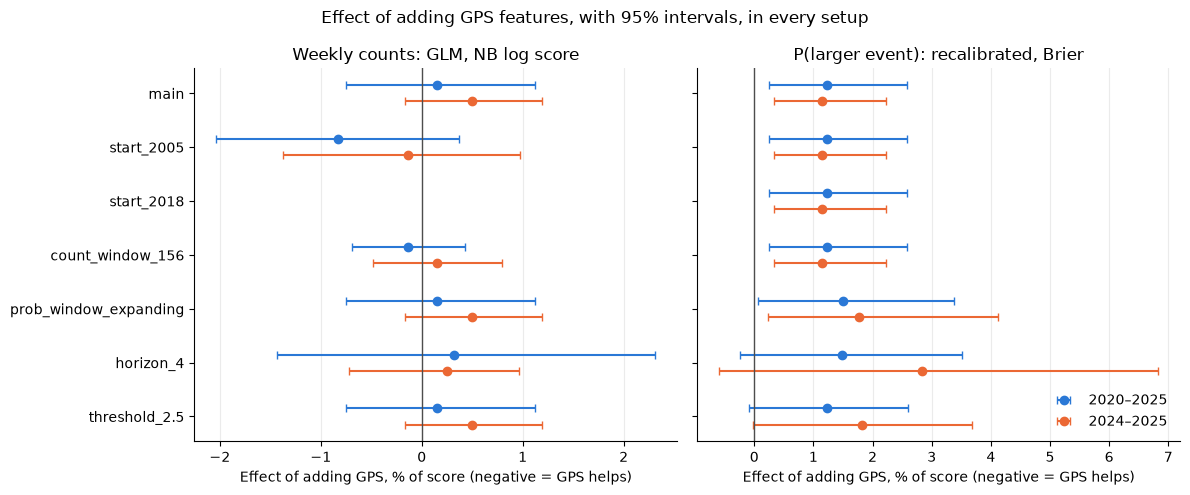

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
names = [s.name for s in settings]
for ax, (comparison, score, title) in zip(axes, [("GPS effect, counts", "NB log score", "Weekly counts: GLM, NB log score"),
                                               ("GPS effect, P(large)", "Brier", "P(larger event): recalibrated, Brier")]):
    for offset, (period, colour) in zip([-0.15, 0.15], [("2020–2025", "#2a78d6"), ("2024–2025", "#eb6834")]):
        ys, est, lo, hi = [], [], [], []
        for i, n in enumerate(names):
            key = (n, comparison, score, period)
            if key in sensitivity.index:
                row = sensitivity.loc[key]
                ys.append(i + offset)
                est.append(row["effect_%"])
                lo.append(row["effect_%"] - row["ci_low_%"])
                hi.append(row["ci_high_%"] - row["effect_%"])
        ax.errorbar(est, ys, xerr=[lo, hi], fmt="o", color=colour, ecolor=colour, capsize=3, label=period)
    ax.axvline(0, color="0.3", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Effect of adding GPS, % of score (negative = GPS helps)")
    ax.grid(True, axis="x", color="0.92", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(range(len(names)), names)
axes[0].invert_yaxis()
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Effect of adding GPS features, with 95% intervals, in every setup")
plt.tight_layout()
fig.savefig("../reports/figures/gps_effect_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

**What section 4 shows:**

- **The conclusion holds in every setup.** For weekly counts, adding GPS changes the GLM's NB log score by between −0.8% and +0.5%, and every 95% interval includes zero; the tests could detect effects of about 0.8–2.7% of the score. For P(larger event), GPS makes the forecast *worse* in every setup (+1.2% to +2.8% of the Brier score), significantly so in most; in no setup does the interval reach a gain of more than 0.6%.
- **Some settings share results by design:** the probability models use a sliding 3-year window, so changing the training *start* (2005, 2018) doesn't change them; the count models don't depend on the magnitude threshold or the probability window. `start_2018` has no NB score (no earlier forecasts to fit the dispersion on).
- **The 4-week horizon, the most promising place for GPS, doesn't change the picture:** +0.3% (interval −1.4% to +2.3%) for counts and +1.5% (−0.3% to +3.5%) for P(M ≥ 3 within 4 weeks). Its intervals are wider: 4-week targets overlap, so there are effectively fewer independent periods.
- **Starting training in 2005 gives GPS its best result** (−0.8% over 2020–2025, interval −2.0% to +0.4%): with the quiet early years included, the uplift level helps a little to separate regimes. It's still not significant, and it disappears in 2024–2025 (−0.1%).
- **Real modelling gains are detected in the same setups.** The GLM beats the rolling mean by 1.2–8.3% of the NB log score, significantly in most settings, and at the 4-week horizon both models clearly beat their baselines (GLM −8.3%; recalibrated −19.6% against climatology over 2020–2025). So these tests can see effects of a few per cent; GPS just doesn't produce one.
- The M ≥ 2.5 threshold gives about 70% more positive weeks (73 against 43) and narrower intervals, and GPS is still harmful (+1.2%, interval −0.1% to +2.6%).